In [77]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import math

In [78]:
!wget https://raw.githubusercontent.com/cobanov/shakespeare-dataset/c69aa9f7ead9c6c2187cb2f61f349390916b2b9a/text/a-midsummer-nights-dream_TXT_FolgerShakespeare.txt

--2026-11-17 12:39:44--  https://raw.githubusercontent.com/cobanov/shakespeare-dataset/c69aa9f7ead9c6c2187cb2f61f349390916b2b9a/text/a-midsummer-nights-dream_TXT_FolgerShakespeare.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 100554 (98K) [text/plain]
Saving to: ‘a-midsummer-nights-dream_TXT_FolgerShakespeare.txt.4’

a-midsummer-nights- 100%[===================>]  98.20K  --.-KB/s    in 0.01s   

2026-11-17 12:39:44 (8.17 MB/s) - ‘a-midsummer-nights-dream_TXT_FolgerShakespeare.txt.4’ saved [100554/100554]



In [79]:
with open('a-midsummer-nights-dream_TXT_FolgerShakespeare.txt', 'r', encoding = 'utf-8') as f:
  text = f.read()

In [80]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(vocab_size)

75


In [81]:
# Hyperparameter
block_size = 256
batch_size = 64
learning_rate = 3e-4
max_iter = 3000
n_embd = 256
n_heads = 4
n_layers = 4
dropout = 0.5
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [82]:
print("Model running on:", device)

Model running on: cuda


In [83]:
stoi = { ch:i for i, ch in enumerate(chars)}
itos = { i:ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

In [84]:
data = torch.tensor(encode(text), dtype = torch.long)

In [85]:
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

In [86]:
def get_batch(split):
  data = train_data if split == 'train' else val_data
  ix = torch.randint(len(data) - block_size - 1, (batch_size,))
  x = torch.stack([data[i:i+block_size] for i in ix])
  y = torch.stack([data[i+1:i+block_size+1] for i in ix])
  x, y = x.to(device), y.to(device)
  return x, y

In [87]:
# Dynamic Tanh
class Dynamic_Tanh(nn.Module):
  def __init__(self, n_dim, alpha_init = 0.5, bias = True):
    super().__init__()
    self.weight = nn.Parameter(torch.ones(n_dim))
    self.bias = nn.Parameter(torch.zeros(n_dim)) if bias else None
    self.alpha = nn.Parameter(torch.ones(1) * alpha_init)

  def forward(self, x):
    x = torch.tanh(self.alpha * x)
    if self.bias is not None:
      return self.weight * x + self.bias
    return self.weight * x

In [88]:
# Multihead Attention
class MultiheadAttention(nn.Module):
  def __init__(self, n_embd, n_heads, block_size, dropout = dropout):
    super().__init__()

    assert n_embd % n_heads == 0

    self.n_heads = n_heads
    self.n_embd = n_embd

    self.head_size = n_embd // n_heads
    self.tril = torch.tril(torch.ones((block_size, block_size)))

    self.qkv = nn.Linear(n_embd, 3 * n_embd, bias = False)
    self.proj = nn.Linear(n_embd, n_embd)

    self.dropout = nn.Dropout(dropout)

  def forward(self, x):
    B, T, C = x.shape
    q, k, v = self.qkv(x).split(self.n_embd, dim = -1)

    q = q.view(B, T, self.n_heads, self.head_size).transpose(1, 2)
    k = k.view(B, T, self.n_heads, self.head_size).transpose(1, 2)
    v = v.view(B, T, self.n_heads, self.head_size).transpose(1, 2)

    wei = q @ k.transpose(-2, -1) / math.sqrt(self.head_size)
    wei = wei.masked_fill(self.tril[:T, :T].to(x.device) == 0, float('-inf'))
    wei = F.softmax(wei, dim = -1)
    wei = self.dropout(wei)

    out = wei @ v
    out = out.transpose(1, 2).contiguous().view(B, T, C)
    out = self.proj(out)

    return out

In [89]:
# Feed Forward Neural Network
class FeedForward(nn.Module):
  def __init__(self,n_embd):
    super().__init__()
    self.net = nn.Sequential(
        nn.Linear(n_embd, 4 * n_embd),
        nn.GELU(),
        nn.Linear(4 * n_embd, n_embd)
    )

  def forward(self, x):
   return self.net(x)

In [90]:
class Block(nn.Module):
  def __init__(self, n_embd, n_head, block_size):
    super().__init__()
    self.dyt1 = Dynamic_Tanh(n_embd)
    self.mha = MultiheadAttention(n_embd, n_head, block_size, dropout = dropout)
    self.dyt2 = Dynamic_Tanh(n_embd)
    self.ffnn = FeedForward(n_embd)

  def forward(self, x):
    x = x + self.mha(self.dyt1(x))
    x = x + self.ffnn(self.dyt2(x))

    return x

In [91]:
class GPTLanguageModel(nn.Module):
  def __init__(self, n_embd, n_heads, vocab_size):
    super().__init__()
    self.block_size = block_size

    self.token_embedding_table = nn.Embedding(vocab_size, n_embd)

    self.position_embedding_table = nn.Embedding(block_size, n_embd)

    self.blocks = nn.Sequential(*[Block(n_embd, n_heads, block_size) for _ in range(n_layers)])

    self.final_norm = Dynamic_Tanh(n_embd)

    self.lm_head = nn.Linear(n_embd, vocab_size)

  def forward(self, idx, targets = None):
    B, T = idx.shape

    assert T <= self.block_size

    token_embd = self.token_embedding_table(idx)
    position_embd = self.position_embedding_table(torch.arange(T, dtype = torch.long, device = idx.device))

    x = self.blocks(token_embd + position_embd)
    x = self.final_norm(x)

    logits = self.lm_head(x)

    if targets is None:
      return logits, None
    else:
      B, T, C = logits.shape
      targets = targets.view(B * T)
      logits = logits.view(B * T, C)

      loss = F.cross_entropy(logits, targets)
    return logits, loss

  def generate(self, idx, max_new_tokens):
    for _ in range(max_new_tokens):
      id_cond = idx[:, -self.block_size:]

      logits, loss = self(id_cond)

      logits = logits[:, -1, :]

      probs = F.softmax(logits, dim = -1)

      idx_next = torch.multinomial(probs, 1)

      idx = torch.cat((idx, idx_next), dim = 1)

    return idx


model_GPT = GPTLanguageModel(n_embd, n_heads, vocab_size).to(device)

In [92]:
# Adam Optimizer
optim = torch.optim.AdamW(model_GPT.parameters(), lr = learning_rate)

In [93]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model_GPT.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(50)
        for k in range(50):
            X, Y = get_batch(split)
            _, loss = model_GPT(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model_GPT.train()
    return out

In [94]:
eval_steps = []
train_losses = []
val_losses = []

for steps in range(max_iter):
  if steps % 100 == 0 or steps == max_iter - 1:
        losses = estimate_loss()
        eval_steps.append(steps)
        train_losses.append(losses['train'])
        val_losses.append(losses['val'])
        print(f"Step {steps}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")


  xb, yb = get_batch('train')
  logits, loss = model_GPT(xb, yb)
  optim.zero_grad(set_to_none = True)
  loss.backward()
  optim.step()

Step 0: train loss 4.3738, val loss 4.3769
Step 100: train loss 2.5920, val loss 2.6822
Step 200: train loss 2.5043, val loss 2.5899
Step 300: train loss 2.4694, val loss 2.5695
Step 400: train loss 2.4409, val loss 2.5206
Step 500: train loss 2.3939, val loss 2.4793
Step 600: train loss 2.3261, val loss 2.4046
Step 700: train loss 2.2604, val loss 2.3447
Step 800: train loss 2.1859, val loss 2.2443
Step 900: train loss 2.1141, val loss 2.1710
Step 1000: train loss 2.0405, val loss 2.0997
Step 1100: train loss 1.9741, val loss 2.0290
Step 1200: train loss 1.9099, val loss 1.9615
Step 1300: train loss 1.8555, val loss 1.9164
Step 1400: train loss 1.8063, val loss 1.8863
Step 1500: train loss 1.7527, val loss 1.8409
Step 1600: train loss 1.7121, val loss 1.8112
Step 1700: train loss 1.6682, val loss 1.7739
Step 1800: train loss 1.6333, val loss 1.7519
Step 1900: train loss 1.6039, val loss 1.7301
Step 2000: train loss 1.5733, val loss 1.7066
Step 2100: train loss 1.5410, val loss 1.6960


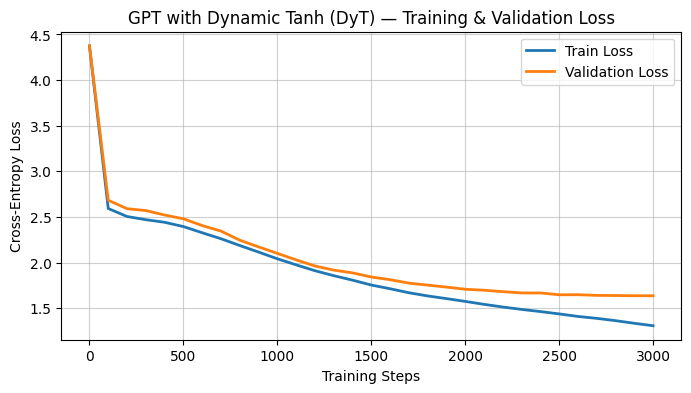

In [95]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(eval_steps, train_losses, label='Train Loss', linewidth=2)
plt.plot(eval_steps, val_losses, label='Validation Loss', linewidth=2)
plt.xlabel('Training Steps')
plt.ylabel('Cross-Entropy Loss')
plt.title('GPT with Dynamic Tanh (DyT) — Training & Validation Loss')
plt.legend()
plt.grid(True, alpha=0.6)
plt.show()

In [96]:
model_GPT.eval()
with torch.no_grad():
    context = torch.zeros([1, 1], dtype=torch.long, device=device)
    print(decode(model_GPT.generate(idx=context, max_new_tokens=500)[0].tolist()))

	[Quin a not, oncry.]
	Dever and in the Duch.
[He exit.]

HELENA
Ay, and, the you moonly. My are what I veer you.
Hit go! Our nother! That yourself, speak Helena!
O, thou rects you part. The could tentle nothing,
To he sew'ritg night,
When sould the may devision did thought never the was
Lysander's flower?

THESEUS  Let noble And you night, starding That us your I confeight
Tomiantial. Now no greamss, chay an deater to steeth,
Dance when Preasseblosson you
you truest a Thisbe's fure day man blood
